In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from torch.utils.data import TensorDataset, DataLoader
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Часть 1

In [2]:
wine_df = pd.read_csv("data/winequality_finished.csv", sep=";")
wine_X = wine_df.drop(["quality"], axis=1)
wine_y= wine_df["quality"]
diabetes_df = pd.read_csv("data/cl_finished.csv", sep=";")
diab_X = diabetes_df.drop(["Diabetes_012"], axis=1)
diab_y = diabetes_df["Diabetes_012"]

In [3]:
print(diab_X.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229781 entries, 0 to 229780
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                229781 non-null  int64
 1   HighChol              229781 non-null  int64
 2   CholCheck             229781 non-null  int64
 3   BMI                   229781 non-null  int64
 4   Smoker                229781 non-null  int64
 5   Stroke                229781 non-null  int64
 6   HeartDiseaseorAttack  229781 non-null  int64
 7   PhysActivity          229781 non-null  int64
 8   Fruits                229781 non-null  int64
 9   Veggies               229781 non-null  int64
 10  HvyAlcoholConsump     229781 non-null  int64
 11  AnyHealthcare         229781 non-null  int64
 12  NoDocbcCost           229781 non-null  int64
 13  GenHlth               229781 non-null  int64
 14  MentHlth              229781 non-null  int64
 15  PhysHlth              229781 non-n

In [4]:
print(wine_X.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   red                   6497 non-null   int64  
 1   fixed acidity         6497 non-null   float64
 2   volatile acidity      6497 non-null   float64
 3   citric acid           6497 non-null   float64
 4   residual sugar        6497 non-null   float64
 5   chlorides             6497 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6497 non-null   float64
 10  sulphates             6497 non-null   float64
 11  alcohol               6497 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 609.2 KB
None


In [5]:
wine_X_train, wine_X_test, wine_y_train, wine_y_test = train_test_split(wine_X, wine_y, test_size=0.2)
diab_X_train, diab_X_test, diab_y_train, diab_y_test = train_test_split(diab_X, diab_y, test_size=0.2, stratify=diab_y)

In [6]:
wine_scaler = StandardScaler()

wine_X_train_fin = wine_scaler.fit_transform(wine_X_train)
wine_X_test_fin = wine_scaler.transform(wine_X_test)

diab_scaler = StandardScaler()

diab_X_train_fin = diab_scaler.fit_transform(diab_X_train)
diab_X_test_fin = diab_scaler.transform(diab_X_test)

**Преобразование в Dataset и Dataloader**

In [7]:
diab_X_train_tensor = torch.tensor(diab_X_train_fin, dtype=torch.float32)
diab_y_train_tensor = torch.tensor(diab_y_train.to_numpy(), dtype=torch.long)

diab_train_dataset = TensorDataset(diab_X_train_tensor,  diab_y_train_tensor)

diab_train_dataloader =  DataLoader(diab_train_dataset, batch_size=32, shuffle=True)

diab_X_test_tensor = torch.tensor(diab_X_test_fin, dtype=torch.float32)
diab_y_test_tensor = torch.tensor(diab_y_test.to_numpy(), dtype=torch.long)

diab_test_dataset = TensorDataset(diab_X_test_tensor, diab_y_test_tensor)

diab_test_dataloader = DataLoader(diab_test_dataset, batch_size=32)

In [8]:
wine_X_train_tensor = torch.tensor(wine_X_train_fin, dtype=torch.float32)
wine_y_train_tensor = torch.tensor(wine_y_train.to_numpy(), dtype=torch.float32)

wine_train_dataset = TensorDataset(wine_X_train_tensor, wine_y_train_tensor)

wine_train_dataloader = DataLoader(wine_train_dataset, batch_size=32, shuffle=True)

wine_X_test_tensor = torch.tensor(wine_X_test_fin, dtype=torch.float32)
wine_y_test_tensor = torch.tensor(wine_y_test.to_numpy(), dtype=torch.float32)

wine_test_dataset = TensorDataset(wine_X_test_tensor, wine_y_test_tensor)

wine_test_dataloader = DataLoader(wine_test_dataset, batch_size=32)

## Формирование нейронной сети

### Регрессия

In [9]:
class RegressionNet(nn.Module):
    def __init__(self):
        super(RegressionNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Linear(12, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15)
        )

        self.layer2 = nn.Sequential(
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.15)
        )

        self.output_layer = nn.Linear(32, 1)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        return self.output_layer(x)


### Классификация

In [10]:
class ClassificationNet(nn.Module):
    def __init__(self):
        super(ClassificationNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Linear(21, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),
        )

        self.layer2 = nn.Sequential(
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.15)
        )

        self.output_layer = nn.Sequential(
            nn.Linear(32, 3)
        )

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        return self.output_layer(x)

## Обучение модели

In [11]:
num_epochs = 20

### Регрессия

In [12]:
reg_model = RegressionNet()

reg_criterion = nn.MSELoss()

reg_optim = optim.Adam(reg_model.parameters(), lr=0.005)

reg_epochs_history = []
reg_loss_history = []

reg_model.train()

for epoch in range(num_epochs):
    epoch_loss = 0.0

    for inputs, targets in wine_train_dataloader:
        reg_optim.zero_grad()

        proba = reg_model(inputs)

        loss = reg_criterion(proba.squeeze(), targets)

        loss.backward()

        reg_optim.step()

        epoch_loss += loss.item()

    average_epoch_loss = epoch_loss/len(wine_train_dataloader)

    reg_epochs_history.append(epoch+1)
    reg_loss_history.append(average_epoch_loss)
    print(f"Эпоха {epoch+1}/{num_epochs} -> Средняя ошибка: {average_epoch_loss:.4f}")

Эпоха 1/20 -> Средняя ошибка: 5.8377
Эпоха 2/20 -> Средняя ошибка: 1.0746
Эпоха 3/20 -> Средняя ошибка: 0.9357
Эпоха 4/20 -> Средняя ошибка: 0.9079
Эпоха 5/20 -> Средняя ошибка: 0.8979
Эпоха 6/20 -> Средняя ошибка: 0.8758
Эпоха 7/20 -> Средняя ошибка: 0.7899
Эпоха 8/20 -> Средняя ошибка: 0.7939
Эпоха 9/20 -> Средняя ошибка: 0.7985
Эпоха 10/20 -> Средняя ошибка: 0.7447
Эпоха 11/20 -> Средняя ошибка: 0.7203
Эпоха 12/20 -> Средняя ошибка: 0.7137
Эпоха 13/20 -> Средняя ошибка: 0.6999
Эпоха 14/20 -> Средняя ошибка: 0.6851
Эпоха 15/20 -> Средняя ошибка: 0.6761
Эпоха 16/20 -> Средняя ошибка: 0.6572
Эпоха 17/20 -> Средняя ошибка: 0.6659
Эпоха 18/20 -> Средняя ошибка: 0.6390
Эпоха 19/20 -> Средняя ошибка: 0.6458
Эпоха 20/20 -> Средняя ошибка: 0.6293


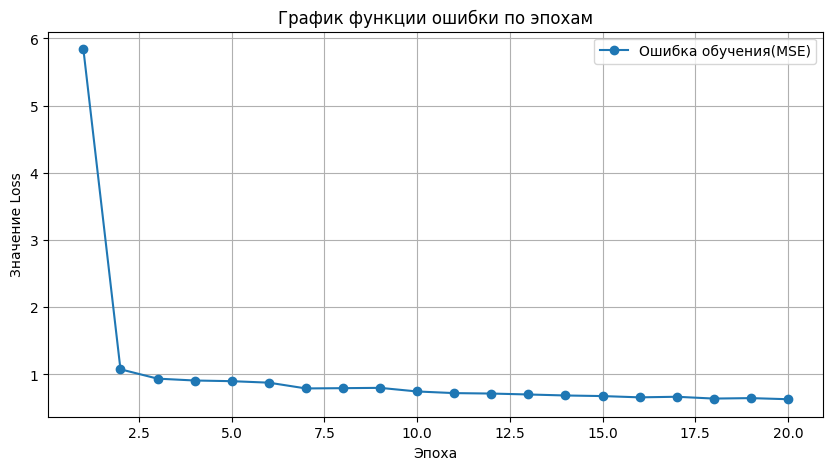

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(reg_epochs_history, reg_loss_history, marker='o', label="Ошибка обучения(MSE)")
plt.title("График функции ошибки по эпохам")
plt.xlabel("Эпоха")
plt.ylabel("Значение Loss")
plt.grid(True)
plt.legend()
plt.show()

### Классификация

In [14]:
clas_model = ClassificationNet()

clas_criterion = nn.CrossEntropyLoss()

clas_optim = optim.Adam(clas_model.parameters(), lr=0.005)

clas_epochs_history = []
clas_loss_history = []

clas_model.train()

for epoch in range(num_epochs):
    epoch_loss = 0.0
    for inputs, targets in diab_train_dataloader:
        clas_optim.zero_grad()

        proba = clas_model(inputs)

        loss = clas_criterion(proba, targets)

        loss.backward()

        clas_optim.step()

        epoch_loss += loss.item()

    average_epoch_loss = epoch_loss / len(diab_train_dataloader)

    clas_epochs_history.append(epoch+1)
    clas_loss_history.append(average_epoch_loss)
    print(f"Эпоха {epoch+1}/{num_epochs} -> Средняя ошибка: {average_epoch_loss:.4f}")


Эпоха 1/20 -> Средняя ошибка: 0.4413
Эпоха 2/20 -> Средняя ошибка: 0.4365
Эпоха 3/20 -> Средняя ошибка: 0.4357
Эпоха 4/20 -> Средняя ошибка: 0.4348
Эпоха 5/20 -> Средняя ошибка: 0.4340
Эпоха 6/20 -> Средняя ошибка: 0.4336
Эпоха 7/20 -> Средняя ошибка: 0.4346
Эпоха 8/20 -> Средняя ошибка: 0.4335
Эпоха 9/20 -> Средняя ошибка: 0.4335
Эпоха 10/20 -> Средняя ошибка: 0.4332
Эпоха 11/20 -> Средняя ошибка: 0.4329
Эпоха 12/20 -> Средняя ошибка: 0.4327
Эпоха 13/20 -> Средняя ошибка: 0.4332
Эпоха 14/20 -> Средняя ошибка: 0.4327
Эпоха 15/20 -> Средняя ошибка: 0.4326
Эпоха 16/20 -> Средняя ошибка: 0.4327
Эпоха 17/20 -> Средняя ошибка: 0.4321
Эпоха 18/20 -> Средняя ошибка: 0.4327
Эпоха 19/20 -> Средняя ошибка: 0.4323
Эпоха 20/20 -> Средняя ошибка: 0.4322


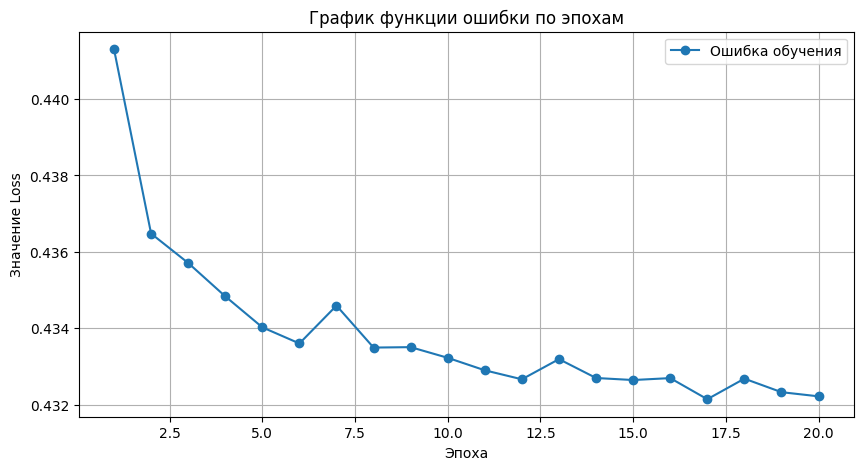

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(clas_epochs_history, clas_loss_history, marker='o', label="Ошибка обучения")
plt.title("График функции ошибки по эпохам")
plt.xlabel("Эпоха")
plt.ylabel("Значение Loss")
plt.grid(True)
plt.legend()
plt.show()

## Оценка моделей

### Метрики регрессии

In [16]:
from sklearn.metrics import mean_squared_error, r2_score

In [17]:
all_reg_targets = []
all_reg_preds = []

reg_model.eval()

with torch.no_grad():
    for inputs, targets in wine_test_dataloader:
        preds = reg_model(inputs).squeeze()

        all_reg_targets.append(targets)
        all_reg_preds.append(preds)

y_reg_true = torch.cat(all_reg_targets).numpy()
y_reg_pred = torch.cat(all_reg_preds).numpy()

print("MSE:", mean_squared_error(y_reg_true, y_reg_pred))
print("R2:", r2_score(y_reg_true, y_reg_pred))

MSE: 0.49636873602867126
R2: 0.34419703483581543


### Метрики классификации

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

all_clas_targets = []
all_clas_preds = []

clas_model.eval()

with torch.no_grad():
    for inputs, targets in diab_test_dataloader:
        logits = clas_model(inputs).squeeze()
        preds = torch.argmax(logits, dim=1)
        all_clas_targets.append(targets)
        all_clas_preds.append(preds)

y_clas_true = torch.cat(all_clas_targets).numpy()
y_clas_pred = torch.cat(all_clas_preds).numpy()

print("Classification report", classification_report(y_clas_true, y_clas_pred))
print("Confusion matrix", confusion_matrix(y_clas_true, y_clas_pred))

Classification report               precision    recall  f1-score   support

           0       0.86      0.96      0.91     38012
           1       0.00      0.00      0.00       926
           2       0.53      0.23      0.32      7019

    accuracy                           0.83     45957
   macro avg       0.46      0.40      0.41     45957
weighted avg       0.79      0.83      0.80     45957

Confusion matrix [[36666     0  1346]
 [  818     0   108]
 [ 5380     0  1639]]


C:\Users\Chaizee\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Chaizee\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Chaizee\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classi

# Часть 2

### Загрузка датасета

In [19]:
petitions_df = pd.read_csv("data/Petitions.csv", sep=",")
petitions_df_20k = petitions_df[:20000]
petitions_df_20k

,id,public_petition_text,reason_category
0,3168490,снег на дороге,Благоустройство
1,3219678,очистить кабельный киоск от рекламы,Благоустройство
2,2963920,"Просим убрать все деревья и кустарники, которы...",Благоустройство
3,3374910,Неудовлетворительное состояние парадной - надп...,Содержание МКД
4,3336285,Граффити,Благоустройство
...,...,...,...
19995,3236633,реклама на водосточной трубе со стороны набере...,Благоустройство
19996,3073950,снег не убран с асфальта,Благоустройство
19997,3022127,"Резкий запах канализации с вентиляции, постоян...",Водоотведение
19998,3178281,18 января 2021 года обращался в Жкс 2 с пробле...,Содержание МКД


In [20]:
print(petitions_df_20k["reason_category"].value_counts())

reason_category
Благоустройство                                                                     11615
Содержание МКД                                                                       4821
Нарушение правил пользования общим имуществом                                         724
Незаконная информационная и (или) рекламная конструкция                               615
Фасад                                                                                 502
Повреждения или неисправность элементов уличной инфраструктуры                        387
Водоснабжение                                                                         272
Кровля                                                                                265
Состояние рекламных или информационных конструкций                                    227
Санитарное состояние                                                                  148
Центральное отопление                                                               

In [21]:
petitions_text = petitions_df["public_petition_text"]

### Очистка датасета

In [22]:
import re
from pymorphy3 import MorphAnalyzer
import nltk
from nltk.corpus import stopwords

In [25]:
nltk.download('stopwords')
russian_stopwords = set(stopwords.words('russian'))

morph = MorphAnalyzer()

def process_text(text: str):
    text = text.lower()

    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'[^а-яё\s]', ' ', text)

    words = text.split()

    processed_words = []

    for word in words:
        if word not in russian_stopwords:
            lemma = morph.parse(word)[0].normal_form

            if lemma not in russian_stopwords and len(lemma) > 1:
                processed_words.append(lemma)

    return processed_words

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Chaizee\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [27]:
petition_process = petitions_text

for i, petition in enumerate(petitions_text, 0):
    petition_process[i] = process_text(petition)


C:\Users\Chaizee\AppData\Local\Temp\ipykernel_22136\2165849304.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  petition_process[i] = process_text(petition)
C:\Users\Chaizee\AppData\Local\Temp\ipykernel_22136\2165849304.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  petition_process[i] = process_text(petition)
C:\Users\Chaizee\AppData\Local\Temp\ipykernel_22136\2165849304.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  peti

In [ ]:
petitions_word_set = set()
for petition in petition_process:
    for word in petition:
        petitions_word_set.add(word)

PETITIONS_SET_LENGTH = len(petitions_word_set)
print(PETITIONS_SET_LENGTH)

16559


In [36]:
idx = {word: i for i, word in enumerate(petitions_word_set)}
idx

{'расширить': 0,
 'тановление': 1,
 'нарушенно': 2,
 'жалеть': 3,
 'около': 4,
 'межэтажный': 5,
 'доставщик': 6,
 'шатко': 7,
 'интересный': 8,
 'зарядка': 9,
 'местахпарковка': 10,
 'дпс': 11,
 'первоначальный': 12,
 'важевский': 13,
 'нагрузка': 14,
 'росиийский': 15,
 'скидывание': 16,
 'отстойник': 17,
 'римский': 18,
 'набросить': 19,
 'портал': 20,
 'леонтьевский': 21,
 'трогуар': 22,
 'прожектор': 23,
 'захарьевский': 24,
 'нессответсвовать': 25,
 'демонтачь': 26,
 'самый': 27,
 'прижим': 28,
 'везде': 29,
 'белые': 30,
 'замёрзнуть': 31,
 'чрезмерный': 32,
 'надлежать': 33,
 'свалиться': 34,
 'закрытый': 35,
 'кораблик': 36,
 'кибальчич': 37,
 'библиотека': 38,
 'завоз': 39,
 'выскрести': 40,
 'витта': 41,
 'пропагандировать': 42,
 'посыпушка': 43,
 'малый': 44,
 'писать': 45,
 'разделительный': 46,
 'неподключённый': 47,
 'контролируещий': 48,
 'заметить': 49,
 'скребковый': 50,
 'бутик': 51,
 'дягтярный': 52,
 'отломать': 53,
 'зарубежье': 54,
 'утаптываться': 55,
 'галактик

In [37]:
def word_to_idx(words):
    idxs = []
    for word in words:
        idxs.append(idx[word])

    return idxs

### Реализация CBoW

In [38]:
EMBEDDINGS_DIM = 128

In [ ]:
class CBoW_emb(nn.Module):
    def __init__(self):
        super(CBoW_emb, self).__init__()

        self.embeddings = nn.Embedding(PETITIONS_SET_LENGTH, embedding_dim=EMBEDDINGS_DIM)

        self.linear = nn.Linear(EMBEDDINGS_DIM, PETITIONS_SET_LENGTH)

    def forward(self, inputs):
        embeds = self.embeddings(input)

        hiden = torch.mean(embeds, dim=1)

        out = self.linear(hiden)

        return out

### Реализации SkipGram

In [ ]:
class SkipGram_emb(nn.module):
    def __init__(self):
        super(SkipGram_emb, self).__init__()

        self.embeddings = nn.Embedding(PETITIONS_SET_LENGTH, embedding_dim=EMBEDDINGS_DIM)

        self.linear = nn.Linear